# Bölüm 2 — Model

Girdi: Bölüm 1'de oluşturulan `ciktilar/analiz_tablosu.csv` (müşteri başına bir satır, yalnızca kesim öncesi bilgiler).

In [1]:
# --- Kurulum ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

CIKTI = '../ciktilar/'
KESIM = pd.Timestamp('2025-06-30')

# --- Veri ---
rfm = pd.read_csv(CIKTI + 'analiz_tablosu.csv', index_col='musteri_id', parse_dates=['ilk_temas_tarihi'])
print('Tablo:', rfm.shape)

# --- 2.1 Hedef dağılımı ---
print(rfm['churn'].value_counts().rename({0: 'kalan (0)', 1: 'terk (1)'}).to_string())
print(f"Terk oranı: %{rfm['churn'].mean() * 100:.1f}")
print(f"Herkese 'terk etmez' diyen modelin doğruluğu: %{(1 - rfm['churn'].mean()) * 100:.1f}")

Tablo: (3974, 17)
churn
kalan (0)    3316
terk (1)      658
Terk oranı: %16.6
Herkese 'terk etmez' diyen modelin doğruluğu: %83.4


In [2]:
# Sonuç (2.1):
# - 3.316 kalan, 658 terk → terk oranı %16,6. Sınıflar dengesiz.
# - Herkese "terk etmez" diyen, hiçbir şey öğrenmemiş bir model bile %83,4 doğruluk alır
#   → doğruluk bu veride anlamlı bir metrik değil. Değerlendirmede ROC-AUC, PR-AUC ve iş metriği kullanılacak.

## 2.2 Model seçimi

**Model: Lojistik regresyon, 6 değişken.**

**Neden lojistik regresyon?**
- Her değişken için bir katsayı verir; etkinin yönü ve gücü doğrudan okunur. İş birimine "bu müşteri neden riskli?" sorusunun cevabı verilebilir.
- Bölüm 1'deki ilişkiler düzenli ve tek yönlü (araç eskidikçe, memnuniyet düştükçe risk artıyor), bu tür ilişkiler için yeterli.

**Neden bu 6 değişken?** Hepsi Bölüm 1'de, modelden önce bulunan güçlü ilişkiler:

| Değişken | Bölüm 1'deki dayanak |
|---|---|
| recency_gun | Bulgu 1: en güçlü ayrışma |
| recency_180_fazlasi | Bulgu 1: risk 6. aya kadar sabit, sonra hızlanıyor. Lojistik regresyon etkiyi düz çizgi varsaydığı için bu kırılma ayrıca veriliyor |
| son_km | Bulgu 2: aynı yaşta km arttıkça terk düşüyor |
| arac_yasi | Bulgu 2: araç eskidikçe terk artıyor |
| ort_memnuniyet | Bulgu 3: düşük memnuniyette terk ~3,5 kat; yaştan bağımsız |
| musteri_tipi_Kurumsal | 1.3: kurumsal %9, bireysel %18 |

**Neden daha fazla değişken ya da daha karmaşık bir model değil?** Bu seçim 2.3'te sınanıyor: Sade model; model gerektirmeyen bir kuralla, bütün değişkenleri kullanan lojistik regresyonla ve daha karmaşık bir modelle (gradient boosting) karşılaştırılıyor.

### Değişkenler

Aday değişkenler üç kurala göre hazırlandı: kesim tarihinde biliniyor olmalı, başka bir değişkenle aynı bilgiyi taşımamalı, model okuyabilmeli. Bütün adaylar 2.3'teki karşılaştırmada kullanılıyor; final model bunlardan 6'sını kullanıyor.

In [3]:
# Model değişkenleri: yalnızca kesimde bilinen bilgiler
# Dışarıda: son_servis (bilgisi recency'de), garantide_arac (araç yaşıyla iç içe, Bölüm 1 Bulgu 2)
X = rfm[['recency_gun', 'frequency', 'monetary', 'ort_memnuniyet', 'anket_cevap_orani',
         'ariza_orani', 'son_km', 'arac_sayisi', 'geri_bildirim_sayisi']].copy()
X['arac_yasi'] = 2025 - rfm['en_yeni_model_yili']
X['musteri_kidemi_gun'] = (KESIM - rfm['ilk_temas_tarihi']).dt.days

# Kategorikler 1/0 sütunlara. Her kategoriden alfabetik ilki referans (Bireysel, Adana, Bayi):
# diğer sütunların hepsi 0 ise o kategori zaten belli. Katsayılar referansa göre fark olarak okunur.
X = X.join(pd.get_dummies(rfm[['musteri_tipi', 'sehir', 'kayit_kanali']], drop_first=True, dtype=int))

# Hiç ankete cevap vermeyenler için bayrak (boşluk ortanca ile doldurulacak, gerçek bir puan değil)
X['anket_cevabi_yok'] = X['ort_memnuniyet'].isna().astype(int)

y = rfm['churn']

print('X:', X.shape)
print('Boş değerler:', X.isna().sum()[X.isna().sum() > 0].to_dict())
print('Değişkenler:', X.columns.tolist())

# 6 ay kırılması: risk 6. aya kadar sabit, sonra hızlanıyor (Bölüm 1, Bulgu 1)
# Lojistik regresyon etkiyi düz çizgi varsaydığı için bu kırılma ayrıca veriliyor
X['recency_180_fazlasi'] = (X['recency_gun'] - 180).clip(lower=0)   # 6 ayı geçmeyenlerde 0

# Final modelin 6 değişkeni (hepsi Bölüm 1'de modelden önce bulunan ilişkiler)
SADE = ['recency_gun', 'recency_180_fazlasi', 'son_km', 'arac_yasi', 'ort_memnuniyet', 'musteri_tipi_Kurumsal']

# Model: boşlukları ortanca ile doldur → ölçekle → lojistik regresyon
# Pipeline sayesinde doldurma ve ölçekleme her doğrulama katında yalnızca eğitim verisinden öğreniliyor (sızıntı yok).
# Ölçekleme, farklı birimlerdeki değişkenlerin (gün, puan, km) katsayılarını karşılaştırılabilir kılıyor.
lojistik = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))

print('Aday değişkenler:', X.shape[1], '| Final modelin değişkenleri:', SADE)

# Sonuç: 3.974 müşteri, 23 aday değişken (11 sayısal + kırılma + 10 kategorik 1/0 + 1 bayrak); final model 6 değişken.
# Boşluk yalnızca monetary (2) ve ort_memnuniyet (47); pipeline içinde ortanca ile doldurulacak.

X: (3974, 22)
Boş değerler: {'monetary': 2, 'ort_memnuniyet': 47}
Değişkenler: ['recency_gun', 'frequency', 'monetary', 'ort_memnuniyet', 'anket_cevap_orani', 'ariza_orani', 'son_km', 'arac_sayisi', 'geri_bildirim_sayisi', 'arac_yasi', 'musteri_kidemi_gun', 'musteri_tipi_Kurumsal', 'sehir_Ankara', 'sehir_Antalya', 'sehir_Bursa', 'sehir_Kocaeli', 'sehir_İstanbul', 'sehir_İzmir', 'kayit_kanali_Mobil Uygulama', 'kayit_kanali_Web', 'kayit_kanali_Çağrı Merkezi', 'anket_cevabi_yok']
Aday değişkenler: 23 | Final modelin değişkenleri: ['recency_gun', 'recency_180_fazlasi', 'son_km', 'arac_yasi', 'ort_memnuniyet', 'musteri_tipi_Kurumsal']


## 2.3 Değerlendirme: metrikler, taban çizgisi ve doğrulama

### Metrikler
İş sorusu: Ekip sınırlı sayıda müşteriyi arayabiliyor. Hangilerini aramalı? Model her müşteriye bir risk puanı verir, en yüksek puanlılar aranır. Bu yüzden modelin işi müşterileri riske göre **doğru sıralamak**.

- **Doğruluk kullanılmadı:** Herkese "kalacak" diyen model %83,4 doğruluk alır ama tek bir terk edeni bulamaz.
- **Sabit olasılık eşiğine dayanan metrikler (F1 vb.) kullanılmadı:** "0,5 üstü riskli" gibi keyfi bir eşik gerektirirler. Burada eşiği belirleyen şey arama kapasitesi; bu yüzden üçüncü metrik eşiği kapasiteye göre koyuyor (en riskli %20).

| Metrik | Basitçe | Rastgele model |
|---|---|---|
| ROC-AUC | Terk eden bir müşteriye, kalan bir müşteriden daha yüksek risk verme olasılığı | 0,5 |
| PR-AUC | Model "riskli" dediğinde ne kadar haklı (terk edenlere odaklı; dengesiz veride daha dürüst) | 0,166 |
| En riskli %20'de yakalanan | En riskli %20 aranırsa terk edenlerin yüzde kaçına ulaşılır (yöneticiye anlatılacak sayı; %20 kapasite varsayımı) | %20 |

### Taban çizgisi
Rastgele bir modeli geçmek kolay. Asıl rakip, model olmadan yarın uygulanabilecek kural: **"En uzun süredir gelmeyeni ara."** Model bunu belirgin şekilde geçmiyorsa, kurulumuna ve bakımına değmez.

### Doğrulama: tabakalı 5 katlı çapraz doğrulama
- Tek bir %20'lik test setinde yalnızca ~130 terk eden olur; sonuç hangi müşterilerin teste düştüğüne bağlı kalır.
- Veri 5 parçaya bölünür; model 4'üyle eğitilip 5.'sinde test edilir, bu 5 kez tekrarlanır. Her müşteri bir kez test edilir ve sonucun ne kadar oynadığı (±) görülür.
- Her parçada terk oranı aynı tutulur (tabakalı).
- Boşluk doldurma ve ölçekleme yalnızca eğitim verisinden öğrenilir (pipeline) → test verisinden sızıntı yok.
- **Sınır:** Bütün müşteriler aynı döneme ait; modelin bir sonraki dönemde de aynı başarıyı göstereceği test edilmedi (bkz. 2.5). Ayrıca değişkenler ve 6. ay eşiği keşifsel analizde bütün veriye bakılarak seçildi; bu, skorları çok hafif iyimser gösterebilir.

In [4]:
def ilk_yuzde_yakalama(y_gercek, skor, oran=0.20):
    """En yüksek skorlu %20'lik dilimde, bütün terk edenlerin yüzde kaçı var?"""
    n = int(len(skor) * oran)
    en_riskli = pd.Series(skor, index=y_gercek.index).nlargest(n).index
    return y_gercek.loc[en_riskli].sum() / y_gercek.sum()

# Taban çizgisi: "en uzun süredir gelmeyeni ara" (yalnızca recency'ye göre sıralama, model gerektirmiyor)
skor = X['recency_gun']
print('Taban çizgisi — sadece recency:')
print(f"  ROC-AUC: {roc_auc_score(y, skor):.3f}")
print(f"  PR-AUC : {average_precision_score(y, skor):.3f}")
print(f"  En riskli %20'de yakalanan terk eden: %{ilk_yuzde_yakalama(y, skor) * 100:.1f}")

Taban çizgisi — sadece recency:
  ROC-AUC: 0.703
  PR-AUC : 0.444
  En riskli %20'de yakalanan terk eden: %45.9


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Libr

                                            ROC-AUC         PR-AUC  En riskli %20
Recency kuralı (taban)                0.703 ± 0.023  0.446 ± 0.023  0.465 ± 0.026
Lojistik, 6 değişken (seçilen)        0.780 ± 0.021  0.506 ± 0.026  0.520 ± 0.023
Lojistik, bütün değişkenler           0.775 ± 0.018  0.505 ± 0.020  0.523 ± 0.036
Gradient boosting, bütün değişkenler  0.771 ± 0.021  0.523 ± 0.025  0.524 ± 0.024


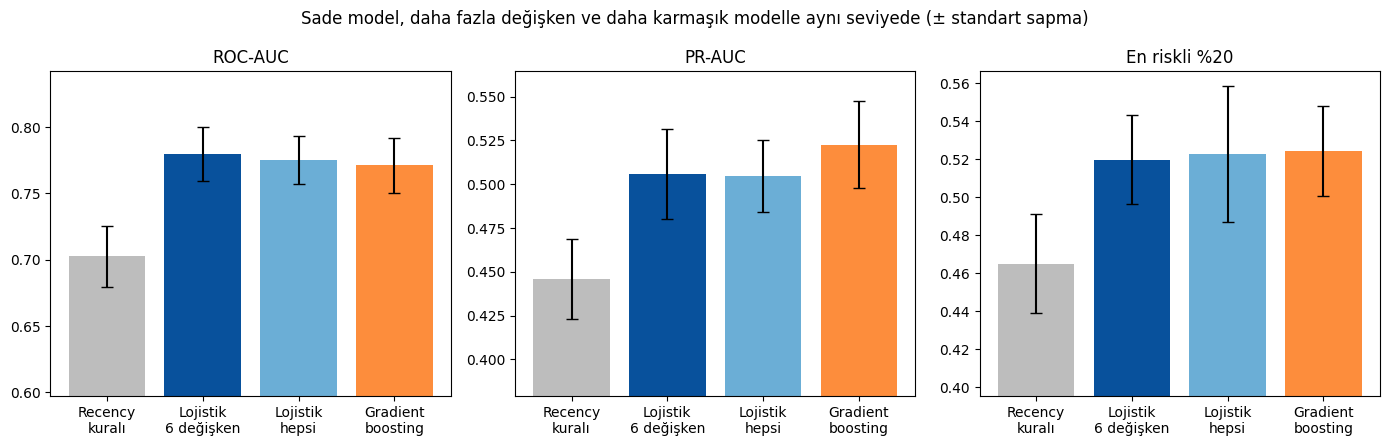

In [5]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 6 ay kırılması: risk 6. aya kadar sabit, sonra hızlanıyor (Bölüm 1, Bulgu 1)
X['recency_180_fazlasi'] = (X['recency_gun'] - 180).clip(lower=0)   # 6 ayı geçmeyenlerde 0
SADE = ['recency_gun', 'recency_180_fazlasi', 'son_km', 'arac_yasi', 'ort_memnuniyet', 'musteri_tipi_Kurumsal']

def degerlendir(model, X, y):
    """5 katlı çapraz doğrulama: her katta eğit, görülmemiş katta ölç → ortalama ve standart sapma."""
    s = {'ROC-AUC': [], 'PR-AUC': [], 'En riskli %20': []}
    for egitim, test in kfold.split(X, y):
        if model is None:                                   # recency kuralı: eğitim yok
            p = X['recency_gun'].iloc[test].values
        else:
            model.fit(X.iloc[egitim], y.iloc[egitim])
            p = model.predict_proba(X.iloc[test])[:, 1]
        yt = y.iloc[test]
        s['ROC-AUC'].append(roc_auc_score(yt, p))
        s['PR-AUC'].append(average_precision_score(yt, p))
        s['En riskli %20'].append(ilk_yuzde_yakalama(yt, p))
    return {k: (np.mean(v), np.std(v)) for k, v in s.items()}

# Pipeline: boşlukları ortanca ile doldur → ölçekle → model (her katta yalnızca eğitim verisinden öğreniliyor)
lojistik = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))
boosting = make_pipeline(SimpleImputer(strategy='median'),
                         HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42))

sonuclar = {
    'Recency kuralı (taban)': degerlendir(None, X, y),
    'Lojistik, 6 değişken (seçilen)': degerlendir(lojistik, X[SADE], y),
    'Lojistik, bütün değişkenler': degerlendir(lojistik, X, y),
    'Gradient boosting, bütün değişkenler': degerlendir(boosting, X, y),
}
tablo = pd.DataFrame({m: {k: f'{o:.3f} ± {s:.3f}' for k, (o, s) in r.items()} for m, r in sonuclar.items()}).T
print(tablo.to_string())

# Grafik (eksenler sıfırdan başlamıyor: farkları görünür kılmak için; gerçek farklar küçük)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
renkler = ['#bdbdbd', '#08519c', '#6baed6', '#fd8d3c']
for ax, metrik in zip(axes, ['ROC-AUC', 'PR-AUC', 'En riskli %20']):
    ort = [r[metrik][0] for r in sonuclar.values()]
    std = [r[metrik][1] for r in sonuclar.values()]
    ax.bar(range(4), ort, yerr=std, color=renkler, capsize=4)
    ax.set_xticks(range(4))
    ax.set_xticklabels(['Recency\nkuralı', 'Lojistik\n6 değişken', 'Lojistik\nhepsi', 'Gradient\nboosting'])
    ax.set_title(metrik)
    ax.set_ylim(min(ort) * 0.85, max(ort) * 1.08)
fig.suptitle('Sade model, daha fazla değişken ve daha karmaşık modelle aynı seviyede (± standart sapma)')
plt.tight_layout()
plt.savefig(CIKTI + 'model_karsilastirma.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Sonuç:
# - Sade model (6 değişken) recency kuralını belirgin şekilde geçiyor: ROC-AUC 0,703 → 0,780,
#   PR-AUC 0,446 → 0,506, en riskli %20'de %46,5 → %52. En riskli ~800 müşteri arandığında ~36 terk edene daha ulaşılıyor.
# - Bütün değişkenler (24) ve gradient boosting, sade modelden belirgin şekilde iyi değil: farklar ± aralığının içinde.
#   Boosting PR-AUC'de biraz önde (0,523 / 0,506) ama hata çizgileri örtüşüyor.
# - Tavan ~0,78 → sınır modelde değil, verideki bilgide. Daha karmaşık model ya da daha fazla değişken bir şey katmıyor.
# - ROC-AUC 0,95'in çok altında → sızıntı işareti yok.
# Karar: Final model = 6 değişkenli lojistik regresyon (aynı başarı, yorumlanabilir, üretimde az bağımlılık).

## 2.4 Final model ve değişken yorumu

Değişkenler ölçeklendiği için katsayılar karşılaştırılabilir. **Risk çarpanı** = değişken 1 standart sapma artınca terk oranının (odds) çarpanı: >1 riski artırır, <1 azaltır.

In [6]:
# Final modeli bütün veriyle eğit (çapraz doğrulama başarıyı ölçmek içindi; şimdi modelin ne öğrendiğine bakıyoruz)
final = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))
final.fit(X[SADE], y)
katsayi = pd.Series(final[-1].coef_[0], index=SADE)

# Kararlılık: 5 katta ayrı ayrı eğitince katsayılar ne kadar oynuyor?
katlar = []
for egitim, _ in kfold.split(X, y):
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(X[SADE].iloc[egitim], y.iloc[egitim])
    katlar.append(pd.Series(m[-1].coef_[0], index=SADE))
katlar = pd.DataFrame(katlar).T

tablo = pd.DataFrame({
    'katsayi': katsayi,
    'risk_carpani': np.exp(katsayi),
    'kat_en_kucuk': katlar.min(axis=1),
    'kat_en_buyuk': katlar.max(axis=1),
    '1_std': X[SADE].std(),                 # 1 standart sapma somut olarak ne kadar?
}).sort_values('katsayi', key=abs, ascending=False)
print(tablo.round(2))

                       katsayi  risk_carpani  kat_en_kucuk  kat_en_buyuk  \
recency_180_fazlasi       0.60          1.82          0.52          0.64   
arac_yasi                 0.46          1.59          0.44          0.50   
son_km                   -0.39          0.67         -0.42         -0.36   
ort_memnuniyet           -0.38          0.68         -0.45         -0.33   
musteri_tipi_Kurumsal    -0.32          0.73         -0.38         -0.29   
recency_gun               0.19          1.21          0.14          0.28   

                        1_std  
recency_180_fazlasi     36.79  
arac_yasi                3.51  
son_km                 561.99  
ort_memnuniyet           0.46  
musteri_tipi_Kurumsal    0.38  
recency_gun             84.83  


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarnin

In [8]:
# Sonuç:
# - 6 katsayının hepsi 5 katta aynı işarette ve dar aralıkta → kararlı, rastlantısal değil.
# - Araç yaşı: 3,5 yaş daha eski → terk oranı ×1,59.
# - son_km: 562 (×1000) km daha fazla → ×0,67 (üçte bir azalıyor). Aynı yaşta yoğun kullanan daha sadık.
# - Memnuniyet: 0,46 puan daha yüksek → ×0,68.
# - Kurumsal müşteri: bireysele göre daha düşük risk (×0,73).
# - Recency iki değişkene bölündü (genel eğim + 6. aydan sonraki ek eğim). 6. aydan sonraki eğim (0,60),
#   genel eğimden (0,19) çok daha güçlü → risk asıl 6. aydan sonra artıyor. Birleşik etkisi bir sonraki hücrede eğriyle.

 30 gün → tahmini terk riski: %9
 90 gün → tahmini terk riski: %10
180 gün → tahmini terk riski: %12
240 gün → tahmini terk riski: %30
300 gün → tahmini terk riski: %56
400 gün → tahmini terk riski: %89


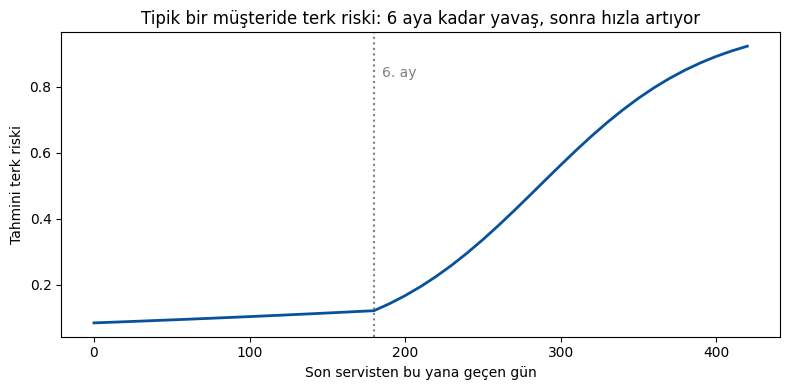

In [7]:
# Amaç: Recency'nin birleşik etkisini göstermek (genel eğim + 6. aydan sonraki ek eğim)
# Diğer 5 değişken tipik (ortanca) bir müşterinin değerinde sabit tutuluyor, sadece recency değişiyor
gunler = np.arange(0, 421, 10)
tipik = X[SADE].median()
senaryo = pd.DataFrame([tipik] * len(gunler))
senaryo['recency_gun'] = gunler
senaryo['recency_180_fazlasi'] = np.clip(gunler - 180, 0, None)
risk = final.predict_proba(senaryo[SADE])[:, 1]

for g in [30, 90, 180, 240, 300, 400]:
    print(f'{g:3d} gün → tahmini terk riski: %{risk[gunler == g][0] * 100:.0f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gunler, risk, color='#08519c', linewidth=2)
ax.axvline(180, color='gray', linestyle=':')
ax.text(185, risk.max() * 0.9, '6. ay', color='gray')
ax.set_xlabel('Son servisten bu yana geçen gün')
ax.set_ylabel('Tahmini terk riski')
ax.set_title('Tipik bir müşteride terk riski: 6 aya kadar yavaş, sonra hızla artıyor')
plt.tight_layout()
plt.savefig(CIKTI + 'recency_risk_egrisi.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Sonuç: Tipik bir müşteride (diğer 5 değişken ortancada) tahmini risk:
#   ilk 6 ay neredeyse sabit (%9 → %12), sonra hızla artıyor: 8. ay %30, 10. ay %56, 13. ay %89.
# Model, Bölüm 1'de veride gördüğümüz eşiği (6. ay) doğru şekilde öğrenmiş.
# İş açısından: Son servisinden 6 ay geçen müşteri takibe alınmalı; 8. aydan sonra risk her ay katlanıyor.

### 2.4 Değişken yorumları

Bütün katsayılar 5 doğrulama katında aynı işarette ve dar aralıkta (kararlı).

**1. Son servisten bu yana geçen süre (recency)**
- *Tahmin gücü:* Terk zaten "gelmemeye başlamak" demek; uzun süredir gelmeyen müşteri sürecin içinde. Etki doğrusal değil: tipik bir müşteride risk ilk 6 ayda %9–12, 8. ayda %30, 10. ayda %56.
- *İş anlamı:* En kolay kullanılabilen sinyal, sistemde her gün güncel. **6. ay** somut bir takip eşiği. Sınırı: Risk yükseldiğinde müşteri zaten gitmeye başlamış olabilir (bkz. 2.5).

**2. Araç yaşı** (risk çarpanı 1,59; 3,5 yaş daha eski)
- *Tahmin gücü:* Eski araç sahipleri daha ucuz servis seçeneklerine yöneliyor. Garantinin görünen etkisi büyük ölçüde bu değişkenin içinde (Bölüm 1, Bulgu 2).
- *İş anlamı:* Elde tutma çabası, yaşlanan araç sahiplerine yönelik olmalı (ör. eski araçlara uygun bakım paketleri). "Garantisi bitene uzatılmış garanti sat" önerisi bu veriyle desteklenmiyor.

**3. Kesim öncesi son km** (risk çarpanı 0,67; ~560 bin km daha fazla)
- *Tahmin gücü:* Aynı yaşta aracı yoğun kullanan müşteri düzenli servise ihtiyaç duyuyor ve yetkili servise bağlı kalıyor. Eski ama az kullanılan araç, yetkili servise getirilmeye değer görülmüyor olabilir.
- *İş anlamı:* En riskli profil "eski ve az kullanılan araç". km sınırı: veride ölçek tutarsız (sözlükteki ×1000 gerçekçi değil), ama araçlar arası sıralama tutarlı.

**4. Ortalama memnuniyet** (risk çarpanı 0,68; 0,46 puan daha yüksek)
- *Tahmin gücü:* Kötü deneyim alternatif arayışını başlatıyor. Etki araç yaşından bağımsız (Bölüm 1, Bulgu 3).
- *İş anlamı:* Doğrudan aksiyon alınabilen tek değişken: Düşük puan veren müşteriye hemen dönüş yapılabilir. Ancak bu bir ilişki; memnuniyeti artırmanın terki ne kadar azaltacağı bu veriyle ölçülemez.

**5. Kurumsal müşteri** (risk çarpanı 0,73; bireysele göre)
- *Tahmin gücü:* Filolar genelde yetkili servisle anlaşmalı; servis seçimi tek bir kişinin kararı değil.
- *İş anlamı:* Elde tutma kaynakları bireysel müşterilere yoğunlaştırılmalı.

Not: Recency iki değişkenle (genel eğim + 6. aydan sonraki ek eğim) modellendiği için 6 katsayı var; tek bir kavram olarak yorumlandı.

## 2.5 Modelin sınırları

**Ana sınır: Model geç uyarıyor.** En güçlü değişken recency; risk asıl 6. aydan sonra yükseliyor. Yani model terki büyük ölçüde müşteri gelmemeye başladıktan sonra fark ediyor. 10 ayı geçen müşterilerin %80'i zaten kaybedilmiş; model onları doğru şekilde "yüksek risk" sayıyor ama bu noktada geri kazanmak zor olabilir. Üretimde en çok endişe edeceğim şey: ekibin zamanını kurtarılması zor müşterilere harcaması.
*Ne yapardım:* Recency henüz düşükken (son 6 ayda gelmiş müşteriler) erken sinyallerin (memnuniyet, araç yaşı, km) ne kadar işe yaradığını ayrıca ölçerdim. Terk edenlerin yarısı bu grupta.

**Hedef tanımı önlenemeyen terki de içeriyor.** Terk edenlerin %22'si aracını satmış (Bölüm 1). Model bu müşterileri de "kaybedilecek" olarak tahmin etmeye çalışıyor; onları aramak boşa harcanan bir çaba.

**Zaman içinde test edilmedi.** Çapraz doğrulama aynı döneme ait müşterileri böldü. Kesimi bir yıl geriye (2024-06-30) çekip 2025 dönemini tahmin ettirmek, modelin zamana dayanıklılığını gösterirdi; zaman yetersizliğinden yapılmadı.

**Üretimde dikkat edilecekler:** Terk etiketi ancak 12 ay sonra belli olduğu için modelin başarısı bir yıl boyunca doğrudan ölçülemez; bu sürede girdi verilerinin dağılımı izlenmeli. Bölüm 1'deki veri kalitesi sorunları (yeni bir tarih biçimi, hatalı tutarlar) üretimde otomatik kontrol edilmeli.

## Risk skorları (Bölüm 3.3 için)

Bölüm 3.3'te "terk riski yüksek ve olumsuz geri bildirimi olan" müşteriler seçilecek. Terk riski bu modelden geliyor; Bölüm 3 ayrı bir notebook olduğu için skorlar bir dosyaya kaydediliyor ve orada okunuyor.

In [12]:
# Final modelin risk skorları → Bölüm 3.3'te yüksek riskli müşterileri seçmek için
risk = pd.DataFrame({'risk_skoru': final.predict_proba(X[SADE])[:, 1], 'churn': y})
risk.to_csv(CIKTI + 'risk_skorlari.csv')
print('Kaydedildi:', risk.shape)
print(risk['risk_skoru'].describe().round(3))

Kaydedildi: (3974, 2)
count    3974.000
mean        0.166
std         0.170
min         0.012
25%         0.065
50%         0.108
75%         0.189
max         0.987
Name: risk_skoru, dtype: float64


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [8]:
# Final modelin risk skorları → Bölüm 3.3'te yüksek riskli müşterileri seçmek için
risk = pd.DataFrame({'risk_skoru': final.predict_proba(X[SADE])[:, 1], 'churn': y})
risk.to_csv(CIKTI + 'risk_skorlari_update.csv')
print('Kaydedildi:', risk.shape)
print(risk['risk_skoru'].describe().round(3))

Kaydedildi: (3974, 2)
count    3974.000
mean        0.166
std         0.170
min         0.012
25%         0.065
50%         0.108
75%         0.189
max         0.987
Name: risk_skoru, dtype: float64


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
